# 01. Exploratory Data Analysis (EDA) — Thyroid Disease Detection

**Project:** Thyroid Disease Detection Using Machine Learning  
**Author:** Venkatesh Devarakonda  
**Curriculum:** B.Tech CSE (AI & ML) — Semester 2-1 Academic Project  

---

## 1. Objective
The goal of this notebook is to perform initial exploratory data analysis on the Thyroid Disease dataset:
- Understand dataset shapes, features, and target classes.
- Inspect missing values and column data types.
- Visualize the distribution of clinical features and blood hormone levels.
- Analyze correlations between features to identify multicollinearity.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Load Datasets
We examine both the raw UCI Thyroid dataset (`data/raw/thyroid_raw.csv`) and the curated modeling dataset (`data/processed/thyroid_processed.csv`).


In [2]:
raw_path = os.path.join("..", "data", "raw", "thyroid_raw.csv")
proc_path = os.path.join("..", "data", "processed", "thyroid_processed.csv")

# If running from project root vs notebooks folder
if not os.path.exists(proc_path):
    proc_path = os.path.join("data", "processed", "thyroid_processed.csv")
if not os.path.exists(raw_path):
    raw_path = os.path.join("data", "raw", "thyroid_raw.csv")

df_proc = pd.read_csv(proc_path)
print("Processed Dataset Shape:", df_proc.shape)
df_proc.head()


Processed Dataset Shape: (20000, 15)


,age,sex,on thyroxine,on antithyroid medication,pregnant,thyroid surgery,lithium,goitre,tumor,TSH,T3,TT4,T4U,FTI,class
0,60,0,0,0,0,0,0,0,0,27.0,1.800000,65.0,0.99,66.0,1
1,45,0,0,0,0,0,0,0,0,7.4,1.400000,108.0,1.08,100.0,1
2,79,0,0,0,0,0,0,0,0,17.0,1.600000,66.0,1.00,65.0,1
3,37,1,0,0,0,0,0,0,0,12.0,2.010828,68.0,0.62,111.0,1
4,54,1,0,0,0,0,0,0,0,14.4,1.100000,51.0,0.68,75.0,1


## 3. Dataset Info and Summary Statistics

In [3]:
# Display column data types and non-null counts
df_proc.info()


<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        20000 non-null  int64  
 1   sex                        20000 non-null  int64  
 2   on thyroxine               20000 non-null  int64  
 3   on antithyroid medication  20000 non-null  int64  
 4   pregnant                   20000 non-null  int64  
 5   thyroid surgery            20000 non-null  int64  
 6   lithium                    20000 non-null  int64  
 7   goitre                     20000 non-null  int64  
 8   tumor                      20000 non-null  int64  
 9   TSH                        20000 non-null  float64
 10  T3                         20000 non-null  float64
 11  TT4                        20000 non-null  float64
 12  T4U                        20000 non-null  float64
 13  FTI                        20000 non-null  float64
 14  c

In [4]:
# Statistical summary of numerical features
df_proc.describe().round(2)


,age,sex,on thyroxine,on antithyroid medication,pregnant,thyroid surgery,lithium,goitre,tumor,TSH,T3,TT4,T4U,FTI,class
count,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00,20000.00
mean,49.57,0.32,0.05,0.00,0.00,0.01,0.00,0.00,0.02,28.08,1.68,67.12,0.99,81.06,7.00
std,16.59,0.47,0.22,0.06,0.06,0.09,0.05,0.05,0.13,67.02,0.77,40.68,0.16,37.25,3.74
min,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05,2.00,0.25,2.00,1.00
25%,41.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.50,1.20,32.00,0.89,54.00,5.50
50%,46.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.30,1.80,64.00,1.00,88.00,8.00
75%,62.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,23.00,2.20,98.00,1.07,110.26,9.50
max,455.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,530.00,10.60,430.00,2.32,395.00,11.00


## 4. Missing Values Inspection

In [5]:
# Verify missing values in the processed dataset
missing = df_proc.isnull().sum()
print("Missing values per column in processed dataset:")
print(missing[missing > 0] if missing.sum() > 0 else "Zero missing values! Clean dataset.")


Missing values per column in processed dataset:
Zero missing values! Clean dataset.


## 5. Target Class Distribution
The 4 primary clinical classes examined:
- **1:** Compensated Hypothyroid (Mild/Subclinical underactivity)
- **7:** Negative (Healthy / Normal euthyroid function)
- **9:** Primary Hypothyroid (Overt thyroid failure)
- **11:** Secondary Hypothyroid (Pituitary failure)


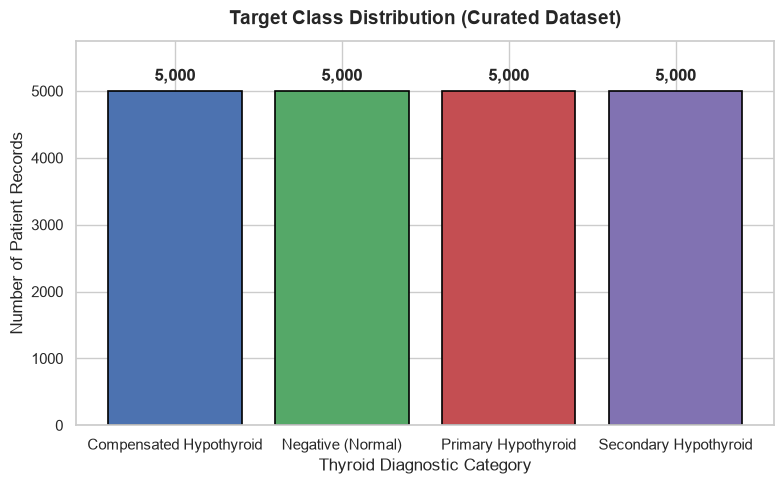

In [6]:
class_names = {
    1: "Compensated Hypothyroid",
    7: "Negative (Normal)",
    9: "Primary Hypothyroid",
    11: "Secondary Hypothyroid"
}

class_counts = df_proc['class'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
labels = [class_names[k] for k in class_counts.index]
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]

bars = plt.bar(labels, class_counts.values, color=colors, edgecolor='black', linewidth=1.2)
plt.title("Target Class Distribution (Curated Dataset)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Thyroid Diagnostic Category", fontsize=12)
plt.ylabel("Number of Patient Records", fontsize=12)
plt.ylim(0, max(class_counts.values) * 1.15)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 100, f"{int(yval):,}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Numerical Feature Distributions and Skewness

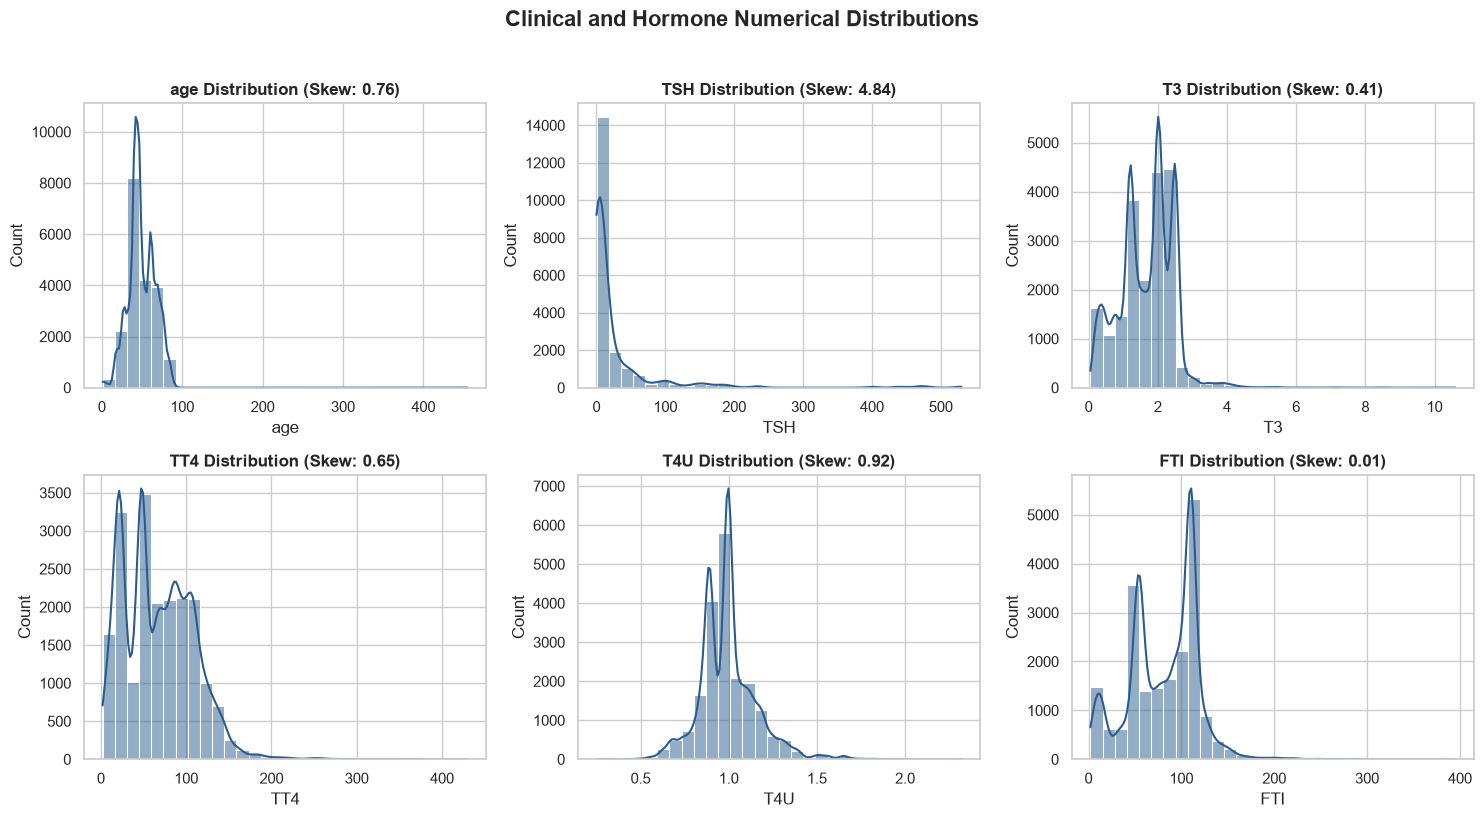

In [7]:
num_cols = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df_proc[col], kde=True, ax=axes[i], color="#2b5c8f", bins=30, edgecolor="white")
    skew_val = df_proc[col].skew()
    axes[i].set_title(f"{col} Distribution (Skew: {skew_val:.2f})", fontweight='bold')

plt.suptitle("Clinical and Hormone Numerical Distributions", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Hormone Boxplots Across Diagnostic Classes

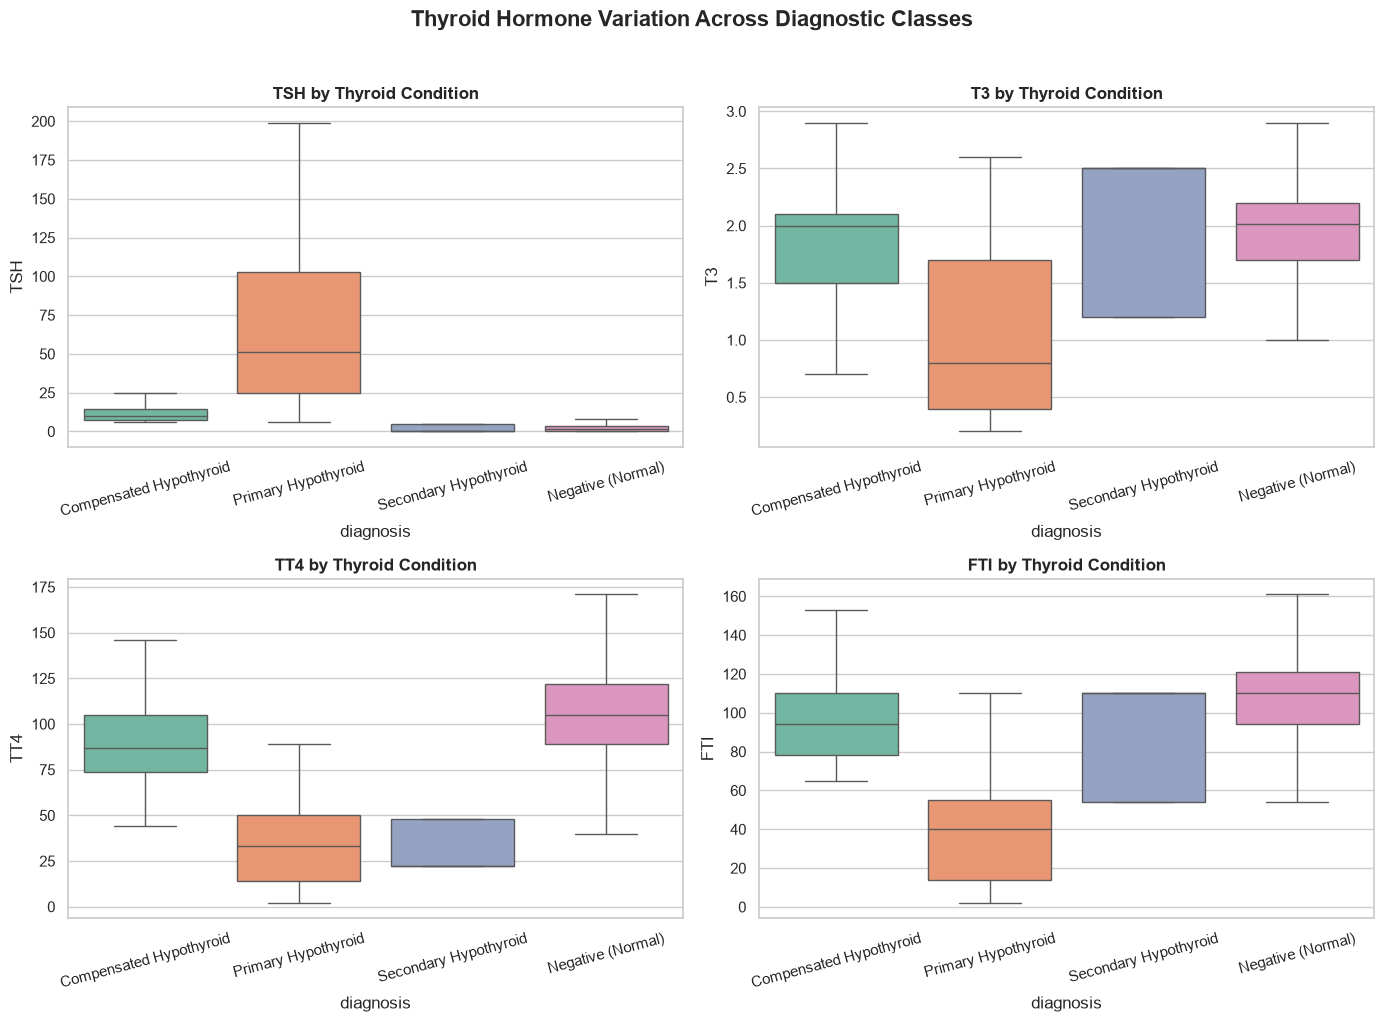

In [8]:
plot_df = df_proc.copy()
plot_df["diagnosis"] = plot_df["class"].map(class_names)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
hormones = ["TSH", "T3", "TT4", "FTI"]

for idx, col in enumerate(hormones):
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(data=plot_df, x="diagnosis", y=col, ax=ax, palette="Set2", hue="diagnosis", legend=False, showfliers=False)
    ax.set_title(f"{col} by Thyroid Condition", fontweight='bold')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle("Thyroid Hormone Variation Across Diagnostic Classes", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 8. Correlation Heatmap

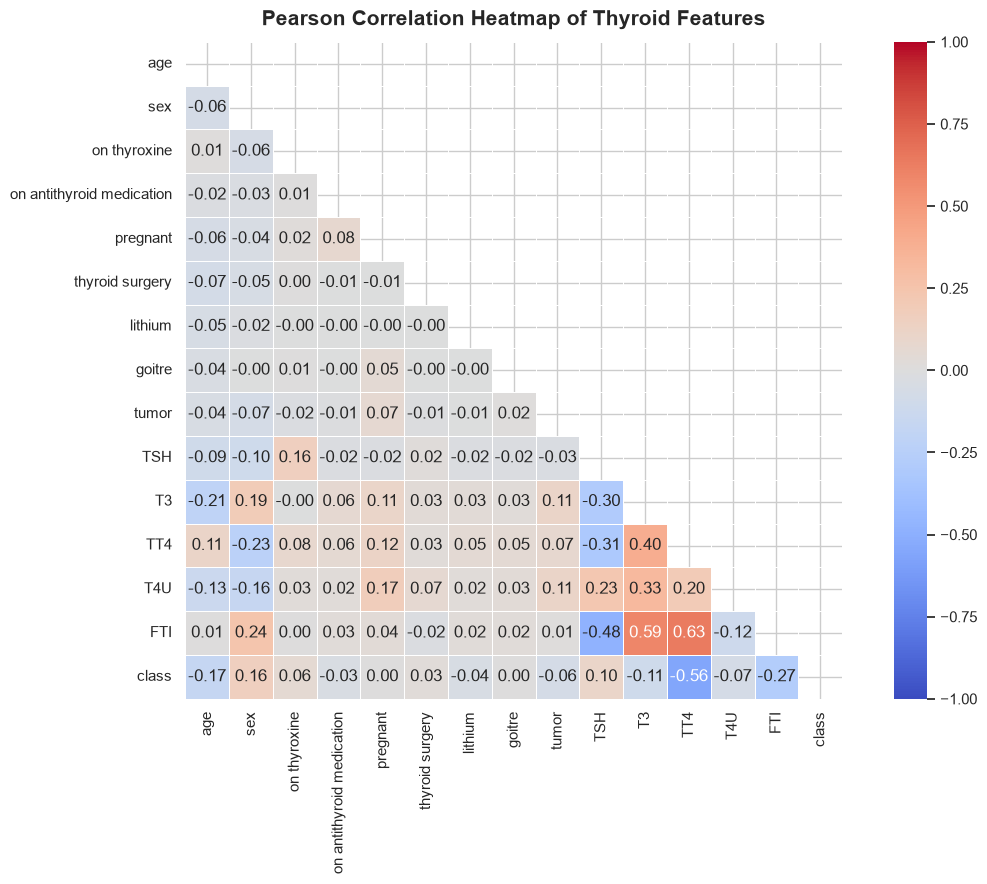

In [9]:
plt.figure(figsize=(12, 9))
corr = df_proc.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Pearson Correlation Heatmap of Thyroid Features", fontsize=15, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 9. Key EDA Findings
1. **Balanced Classes:** Exactly 5,000 records per class (total 20,000), preventing majority-class bias.
2. **Hormone Differentiation:** Primary Hypothyroid patients show markedly elevated TSH and depressed FTI and TT4.
3. **Collinearity:** Strong correlation between `TT4` and `FTI` ($pprox 0.79$), consistent with endocrine biology ($FTI = TT4 / T4U$).
4. **Data Hygiene:** No missing values or irregular string tokens remaining in the curated dataset.
